# Decision Trees
**IBM Machine Learning with Python Lab**

Estimated time needed: **25 minutes**

---

### Objectives
After completing this lab you will be able to:
- Develop a classification model using Decision Tree Algorithm
- Apply Decision Tree classification on a real world dataset.

### Introduction
This lab explores decision tree classification, a powerful machine learning technique for making data-driven decisions. You will learn to build, visualize, and evaluate decision trees using a real-world dataset. The dataset used in this lab is that of Drug prediction based on the health parameters of a patient.

## 1. Importing Libraries

First, to make sure that the required libraries are available, execute the cell below.

In [1]:
# Make sure the required libraries are available
# !pip install numpy==2.2.0
# !pip install pandas==2.2.3
# !pip install scikit-learn==1.6.0
# !pip install matplotlib==3.9.3

Now import the required libraries for this lab.

In [2]:
import numpy as np 
import pandas as pd
from matplotlib import pyplot as plt
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn import metrics

%matplotlib inline

import warnings
warnings.filterwarnings('ignore')

## 2. About the Dataset

Imagine that you are a medical researcher compiling data for a study. You have collected data about a set of patients, all of whom suffered from the same illness. During their course of treatment, each patient responded to one of 5 medications, Drug A, Drug B, Drug C, Drug X and Drug Y.

Part of your job is to build a model to find out which drug might be appropriate for a future patient with the same illness. The features of this dataset are the Age, Sex, Blood Pressure, and Cholesterol of the patients, and the target is the drug that each patient responded to.

It is a sample of a multiclass classifier, and you can use the training part of the dataset to build a decision tree, and then use it to predict the class of an unknown patient or to prescribe a drug to a new patient.

### Downloading the Data
To download the data, we will use direct URL to download it from IBM Object Storage.

In [3]:
path = 'https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-ML0101EN-SkillsNetwork/labs/Module%203/data/drug200.csv'
my_data = pd.read_csv(path)
my_data

,Age,Sex,BP,Cholesterol,Na_to_K,Drug
0,23,F,HIGH,HIGH,25.355,drugY
1,47,M,LOW,HIGH,13.093,drugC
2,47,M,LOW,HIGH,10.114,drugC
3,28,F,NORMAL,HIGH,7.798,drugX
4,61,F,LOW,HIGH,18.043,drugY
...,...,...,...,...,...,...
195,56,F,LOW,HIGH,11.567,drugC
196,16,M,LOW,HIGH,12.006,drugC
197,52,M,NORMAL,HIGH,9.894,drugX
198,23,M,NORMAL,NORMAL,14.020,drugX


## 3. Data Analysis and Pre-processing

You should apply some basic analytics steps to understand the data better. First, let us gather some basic information about the dataset.

In [4]:
my_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Age          200 non-null    int64  
 1   Sex          200 non-null    str    
 2   BP           200 non-null    str    
 3   Cholesterol  200 non-null    str    
 4   Na_to_K      200 non-null    float64
 5   Drug         200 non-null    str    
dtypes: float64(1), int64(1), str(4)
memory usage: 9.5 KB


This tells us that 4 out of the 6 features of this dataset are categorical, which will have to be converted into numerical ones to be used for modeling. For this, we can make use of LabelEncoder from the Scikit-Learn library.

In [5]:
label_encoder = LabelEncoder()
my_data['Sex'] = label_encoder.fit_transform(my_data['Sex']) 
my_data['BP'] = label_encoder.fit_transform(my_data['BP'])
my_data['Cholesterol'] = label_encoder.fit_transform(my_data['Cholesterol']) 
my_data

,Age,Sex,BP,Cholesterol,Na_to_K,Drug
0,23,0,0,0,25.355,drugY
1,47,1,1,0,13.093,drugC
2,47,1,1,0,10.114,drugC
3,28,0,2,0,7.798,drugX
4,61,0,1,0,18.043,drugY
...,...,...,...,...,...,...
195,56,0,1,0,11.567,drugC
196,16,1,1,0,12.006,drugC
197,52,1,2,0,9.894,drugX
198,23,1,2,1,14.020,drugX


With this, you now have 5 parameters that can be used for modeling and 1 feature as the target variable. We can see from comparison of the data before Label encoding and after it, to note the following mapping:
- For parameter 'Sex' : $M \rightarrow 1, F \rightarrow 0$
- For parameter 'BP' : $High \rightarrow 0, Low \rightarrow 1, Normal \rightarrow 2$
- For parameter 'Cholesterol' : $High \rightarrow 0, Normal \rightarrow 1$

You can also check if there are any missing values in the dataset.

In [6]:
my_data.isnull().sum()

Age            0
Sex            0
BP             0
Cholesterol    0
Na_to_K        0
Drug           0
dtype: int64

This tells us that there are no missing values in any of the fields.

To evaluate the correlation of the target variable with the input features, it will be convenient to map the different drugs to a numerical value. Execute the following cell to achieve the same.

In [7]:
custom_map = {'drugA':0,'drugB':1,'drugC':2,'drugX':3,'drugY':4}
my_data['Drug_num'] = my_data['Drug'].map(custom_map)
my_data

,Age,Sex,BP,Cholesterol,Na_to_K,Drug,Drug_num
0,23,0,0,0,25.355,drugY,4
1,47,1,1,0,13.093,drugC,2
2,47,1,1,0,10.114,drugC,2
3,28,0,2,0,7.798,drugX,3
4,61,0,1,0,18.043,drugY,4
...,...,...,...,...,...,...,...
195,56,0,1,0,11.567,drugC,2
196,16,1,1,0,12.006,drugC,2
197,52,1,2,0,9.894,drugX,3
198,23,1,2,1,14.020,drugX,3


You can now use the `corr()` function to find the correlation of the input variables with the target variable.

---

### Practice question
Write the code to find the correlation of the input variables with the target variable and identify the features most significantly affecting the target.

<details><summary>Click here for the solution</summary>

```python
corr_matrix = my_data.drop('Drug', axis=1).corr()
print("Correlation with target variable Drug_num:")
print(corr_matrix['Drug_num'].sort_values(ascending=False))
```

</details>

In [8]:
# Correlation matrix of numerical variables with Drug_num
corr_matrix = my_data.drop('Drug', axis=1).corr()
print("Correlation of features with Drug_num:")
print(corr_matrix['Drug_num'].sort_values(ascending=False))

# Identify features most significantly affecting the target
most_correlated = corr_matrix['Drug_num'].drop('Drug_num').abs().sort_values(ascending=False)
print("\nFeatures most significantly affecting the target (by absolute correlation):")
print(most_correlated)

Correlation of features with Drug_num:
Drug_num       1.000000
Na_to_K        0.589120
BP             0.372868
Cholesterol    0.055629
Age           -0.004828
Sex           -0.098573
Name: Drug_num, dtype: float64

Features most significantly affecting the target (by absolute correlation):
Na_to_K        0.589120
BP             0.372868
Sex            0.098573
Cholesterol    0.055629
Age            0.004828
Name: Drug_num, dtype: float64


We can also understand the distribution of the dataset by plotting the count of the records with each drug recommendation.

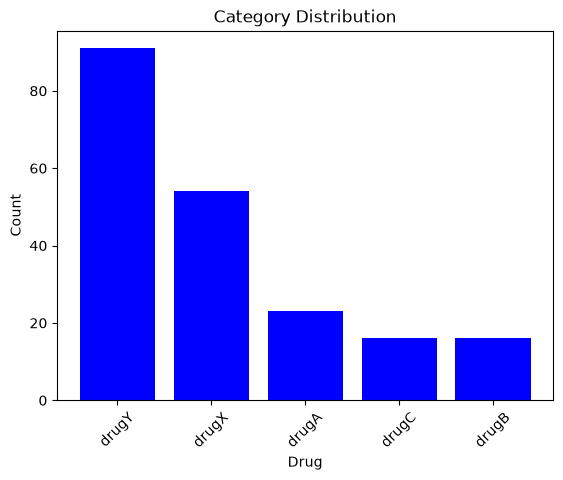

In [9]:
category_counts = my_data['Drug'].value_counts()

# Plot the count plot
plt.bar(category_counts.index, category_counts.values, color='blue')
plt.xlabel('Drug')
plt.ylabel('Count')
plt.title('Category Distribution')
plt.xticks(rotation=45)  # Rotate labels for better readability if needed
plt.show()

This shows us the distribution of the different classes, clearly indicating that Drug X and Drug Y have many more records in comparison to the other 3.

## 4. Modeling

For modeling this dataset with a Decision tree classifier, we first split the dataset into training and testing subsets. For this, we separate the target variable from the input variables.

In [10]:
y = my_data['Drug']
X = my_data.drop(['Drug','Drug_num'], axis=1)

Now, use the `train_test_split()` function to separate the training data from the testing data. We can make use of 30% of the data for testing and the rest for training the Decision tree.

In [11]:
X_trainset, X_testset, y_trainset, y_testset = train_test_split(X, y, test_size=0.3, random_state=32)

You can now define the Decision tree classifier as `drugTree` and train it with the training data.

In [12]:
drugTree = DecisionTreeClassifier(criterion="entropy", max_depth = 4)

drugTree.fit(X_trainset,y_trainset)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'entropy'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",4
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of sampl

## 5. Evaluation

Now that you have trained the decision tree, we can use it to generate the predictions on the test set.

In [13]:
tree_predictions = drugTree.predict(X_testset)

We can now check the accuracy of our model by using the accuracy metric.

In [14]:
print("Decision Trees's Accuracy: ", metrics.accuracy_score(y_testset, tree_predictions))

Decision Trees's Accuracy:  0.9833333333333333


This means that the model was able to correctly identify the labels of 98.33%, i.e. 59 out of 60 test samples.

## 6. Visualize the Tree

To understand the classification criteria derived by the Decision Tree, we may generate the tree plot.

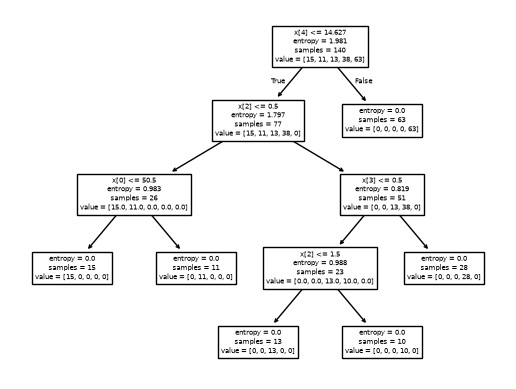

In [15]:
plot_tree(drugTree)
plt.show()

To interpret the decisions more clearly, let's also render an enhanced visualization with feature names, class colors, and rounded nodes:

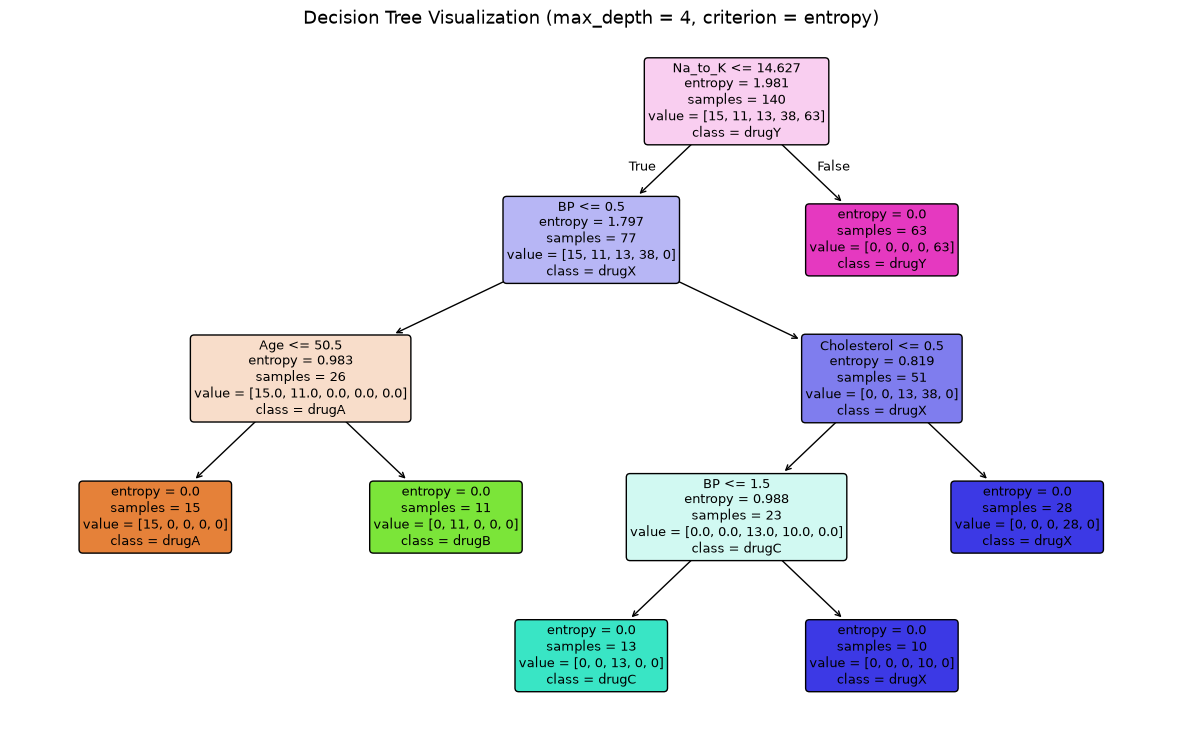

In [16]:
# Enhanced tree visualization
plt.figure(figsize=(15, 9))
plot_tree(
    drugTree,
    feature_names=list(X.columns),
    class_names=sorted(y.unique()),
    filled=True,
    rounded=True,
    fontsize=9
)
plt.title("Decision Tree Visualization (max_depth = 4, criterion = entropy)", fontsize=13)
plt.show()

From this tree, we can derive the criteria developed by the model to identify the class of each training sample. We can interpret them by tracing the criteria defined by tracing down from the root to the tree's leaf nodes.

For instance, the decision criterion for Drug Y is $Na\_to\_K > 14.627$.

---

### Practice Question:
Along similar lines, identify the decision criteria for all other classes.

<details><summary>Click here for the solution</summary>

By tracing the tree from root to leaves:
- **Drug Y**: $Na\_to\_K > 14.627$
- **Drug A**: $Na\_to\_K \le 14.627$ and $BP = 0$ (High BP) and $Age \le 50.5$
- **Drug B**: $Na\_to\_K \le 14.627$ and $BP = 0$ (High BP) and $Age > 50.5$
- **Drug C**: $Na\_to\_K \le 14.627$ and $BP = 1$ (Low BP) and $Cholesterol = 0$ (High Cholesterol)
- **Drug X**: $Na\_to\_K \le 14.627$ and ($BP = 2$ [Normal BP] or ($BP = 1$ [Low BP] and $Cholesterol = 1$ [Normal Cholesterol]))

</details>

In [17]:
# Programmatically extracting the decision rules as text
print("--- Text Representation of Decision Rules ---")
print(export_text(drugTree, feature_names=list(X.columns)))

--- Text Representation of Decision Rules ---
|--- Na_to_K <= 14.63
|   |--- BP <= 0.50
|   |   |--- Age <= 50.50
|   |   |   |--- class: drugA
|   |   |--- Age >  50.50
|   |   |   |--- class: drugB
|   |--- BP >  0.50
|   |   |--- Cholesterol <= 0.50
|   |   |   |--- BP <= 1.50
|   |   |   |   |--- class: drugC
|   |   |   |--- BP >  1.50
|   |   |   |   |--- class: drugX
|   |   |--- Cholesterol >  0.50
|   |   |   |--- class: drugX
|--- Na_to_K >  14.63
|   |--- class: drugY



---

### Practice Question:
If the max depth of the tree is reduced to 3, how would the performance of the model be affected?

<details><summary>Click here for the solution</summary>

```python
drugTree_depth3 = DecisionTreeClassifier(criterion="entropy", max_depth=3)
drugTree_depth3.fit(X_trainset, y_trainset)
predictions_depth3 = drugTree_depth3.predict(X_testset)
print("Accuracy with max_depth=3:", metrics.accuracy_score(y_testset, predictions_depth3))
```

**Observation:**
Reducing `max_depth` to 3 reduces accuracy from **98.33%** to **81.67%**. A tree of depth 3 cannot perform the fourth-level splits necessary to separate Drug A from Drug B or Drug C from Drug X, resulting in underfitting.

</details>

In [18]:
# Retraining with max_depth = 3
drugTree_depth3 = DecisionTreeClassifier(criterion="entropy", max_depth=3)
drugTree_depth3.fit(X_trainset, y_trainset)
predictions_depth3 = drugTree_depth3.predict(X_testset)

acc_d4 = metrics.accuracy_score(y_testset, tree_predictions)
acc_d3 = metrics.accuracy_score(y_testset, predictions_depth3)

print("Decision Tree Accuracy (max_depth = 4): %.4f (%.2f%%)" % (acc_d4, acc_d4 * 100))
print("Decision Tree Accuracy (max_depth = 3): %.4f (%.2f%%)" % (acc_d3, acc_d3 * 100))
print("Accuracy Difference:                  -%.2f%%" % ((acc_d4 - acc_d3) * 100))

Decision Tree Accuracy (max_depth = 4): 0.9833 (98.33%)
Decision Tree Accuracy (max_depth = 3): 0.8167 (81.67%)
Accuracy Difference:                  -16.67%


## 7. Model Diagnostics: Depth vs Accuracy Analysis

To see why `max_depth = 4` is the optimal hyperparameter for this dataset, let's evaluate model performance across different tree depths from 1 to 6.

In [19]:
# Evaluating performance across depths 1 to 6
depth_comparison = []

for d in range(1, 7):
    model = DecisionTreeClassifier(criterion="entropy", max_depth=d, random_state=32)
    model.fit(X_trainset, y_trainset)
    train_acc = metrics.accuracy_score(y_trainset, model.predict(X_trainset))
    test_acc = metrics.accuracy_score(y_testset, model.predict(X_testset))
    depth_comparison.append({
        'Max Depth': d,
        'Train Accuracy (%)': np.round(100 * train_acc, 2),
        'Test Accuracy (%)': np.round(100 * test_acc, 2),
        'Status': 'Underfitting' if test_acc < 0.95 else ('Optimal Fit' if d == 4 else 'Sufficient Depth')
    })

comparison_df = pd.DataFrame(depth_comparison)
comparison_df

,Max Depth,Train Accuracy (%),Test Accuracy (%),Status
0,1,72.14,71.67,Underfitting
1,2,82.86,85.00,Underfitting
2,3,92.86,81.67,Underfitting
3,4,100.00,98.33,Optimal Fit
4,5,100.00,98.33,Sufficient Depth
5,6,100.00,98.33,Sufficient Depth


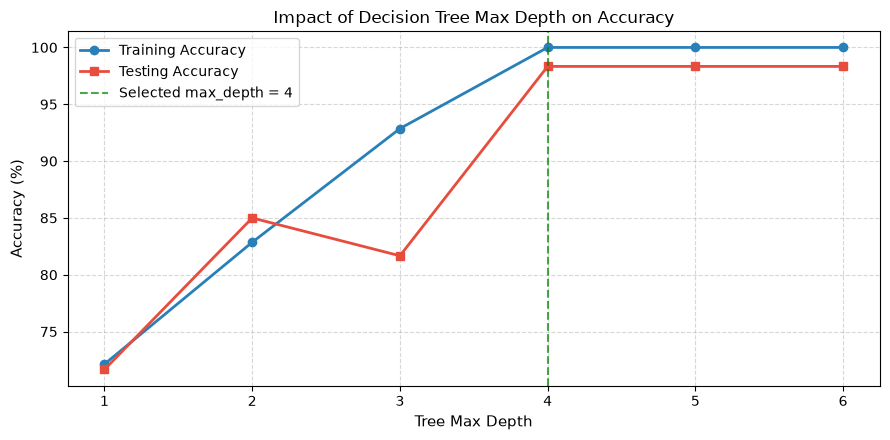

In [20]:
# Plotting Accuracy vs Max Depth
plt.figure(figsize=(9, 4.5))
plt.plot(comparison_df['Max Depth'], comparison_df['Train Accuracy (%)'], marker='o', linewidth=2, color='#2980b9', label='Training Accuracy')
plt.plot(comparison_df['Max Depth'], comparison_df['Test Accuracy (%)'], marker='s', linewidth=2, color='#e74c3c', label='Testing Accuracy')
plt.axvline(4, color='green', linestyle='--', alpha=0.7, label='Selected max_depth = 4')

plt.title("Impact of Decision Tree Max Depth on Accuracy", fontsize=12)
plt.xlabel("Tree Max Depth", fontsize=11)
plt.ylabel("Accuracy (%)", fontsize=11)
plt.xticks(range(1, 7))
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

---
## Congratulations! You're ready to move on to your next lesson!